# Finlora Fintech — Fraud Detection & Risk Scoring
## Notebook 02: Exploratory Data Analysis

**Goal of this notebook (Project Task — phases 3 & 4).**
Understand *who and what* gets flagged as fraud, and which **behavioural
signals** separate fraud from legitimate activity. The findings feed the
feature list used in notebook 03.

We split EDA into two parts, mirroring the task:
1. **Fraud rates and transaction patterns** — fraud rate by account type, KYC tier,
   channel, merchant category, currency, status, hour, day; amount distributions.
2. **Behavioural signals** — `amount_to_avg_ratio`, `transaction_velocity_1h`,
   `is_new_device`, `is_cross_border`, `account_age_days`; correlation matrix;
   a rule-based baseline; a one-page summary of which features carry signal.

All charts are saved to `eda_reports/` so they can be embedded in the final report.

In [1]:
# --- Path setup ------------------------------------------------------------
# These notebooks share files through the `processed_data/` folder, so each
# notebook must know where the project lives. We derive it from this file's
# location. If you move the notebooks, just set PROJECT_ROOT manually below.
import os, sys
try:
    # When run as a script (kernel prints __file__-like info) this works:
    PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
except Exception:
    PROJECT_ROOT = "/home/z/my-project"

# Fallback to the known sandbox location if the derived path does not contain upload/
if not os.path.isdir(os.path.join(PROJECT_ROOT, "upload")):
    PROJECT_ROOT = "/home/z/my-project"

UPLOAD_DIR    = os.path.join(PROJECT_ROOT, "upload")
PROCESSED_DIR = os.path.join(PROJECT_ROOT, "download", "processed_data")
MODELS_DIR    = os.path.join(PROCESSED_DIR, "models")
EDA_DIR       = os.path.join(PROJECT_ROOT, "download", "eda_reports")
APP_DIR       = os.path.join(PROJECT_ROOT, "download", "streamlit_app")

for d in (PROCESSED_DIR, MODELS_DIR, EDA_DIR, APP_DIR):
    os.makedirs(d, exist_ok=True)

print("PROJECT_ROOT :", PROJECT_ROOT)
print("UPLOAD_DIR    :", UPLOAD_DIR)
print("PROCESSED_DIR :", PROCESSED_DIR)

PROJECT_ROOT : /home/z/my-project
UPLOAD_DIR    : /home/z/my-project/upload
PROCESSED_DIR : /home/z/my-project/download/processed_data


In [2]:
# --- Imports ---------------------------------------------------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings, json, pickle, os

warnings.filterwarnings("ignore")

# Matplotlib font setup that renders Chinese/CJK and special chars if present.
import matplotlib.font_manager as fm
try:
    fm.fontManager.addfont("/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf")
except Exception:
    pass
plt.rcParams["font.sans-serif"] = ["DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
sns.set_style("whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

### 1. Load the cleaned dataset

In [3]:
df = pd.read_csv(os.path.join(PROCESSED_DIR, "test_cleaned_data.csv"))
print("df shape:", df.shape)
print("fraud rate:", round(df["is_fraud"].mean()*100, 3), "%")
df.head()

df shape: (126000, 30)
fraud rate: 2.66 %


,transaction_id,account_id,account_type,kyc_tier,timestamp,day_of_week,hour_of_day,description,merchant_name,merchant_category,...,is_new_device,account_age_days,status,is_fraud,device_id_missing,is_new_device_missing,is_refund,account_holder_name,account_created_date,personal_spend_baseline_usd
0,FLR250216186265,FLR-ACC-100000,Individual,Tier3_Enhanced,2025-02-16 14:55:35,Sunday,14,CNP PURCHASE - BOLT,Bolt,Travel,...,-1,903,Completed,0,1,1,0,Amaka Okafor,2022-08-28,63.23
1,FLR250423143305,FLR-ACC-100000,Individual,Tier3_Enhanced,2025-04-23 13:35:40,Wednesday,13,WEB PURCHASE - SLACK,Slack,Subscription/SaaS,...,-1,969,Declined,0,1,1,0,Amaka Okafor,2022-08-28,63.23
2,FLR250424154897,FLR-ACC-100000,Individual,Tier3_Enhanced,2025-04-24 12:30:34,Thursday,12,MOBILE PURCHASE - JUSTRITE SUPERSTORE,Justrite Superstore,Groceries,...,0,970,Completed,0,0,0,0,Amaka Okafor,2022-08-28,63.23
3,FLR250428101772,FLR-ACC-100000,Individual,Tier3_Enhanced,2025-04-28 14:41:59,Monday,14,CNP PURCHASE - ADOBE CREATIVE CLOUD,Adobe Creative Cloud,Subscription/SaaS,...,-1,974,Completed,0,1,1,0,Amaka Okafor,2022-08-28,63.23
4,FLR250628102827,FLR-ACC-100000,Individual,Tier3_Enhanced,2025-06-28 16:15:47,Saturday,16,MOBILE PURCHASE - APPLE STORE,Apple Store,Electronics,...,0,1035,Declined,0,0,0,0,Amaka Okafor,2022-08-28,63.23


## Part A — Fraud rates and transaction patterns

### 2. Overall fraud rate and fraud rate by segment

For each categorical segment we compute:
- the **count** of transactions,
- the **fraud rate** (% of transactions that are fraud).

Fraud rate is the right metric here (not raw fraud count) because segments have
very different sizes — we want to know *where fraud concentrates*, not just where
there are many transactions.

In [4]:
def fraud_rate_by(df, col):
    """Group by col, return count, fraud count and fraud rate."""
    g = df.groupby(col).agg(
        n=("is_fraud", "size"),
        fraud=("is_fraud", "sum"),
    )
    g["fraud_rate_pct"] = (g["fraud"] / g["n"] * 100).round(3)
    return g.sort_values("fraud_rate_pct", ascending=False)

overall = df["is_fraud"].mean() * 100
print(f"OVERALL fraud rate: {overall:.3f}%\n")

for col in ["account_type", "kyc_tier", "channel", "merchant_category", "currency"]:
    print(f"\n=== Fraud rate by {col} ===")
    print(fraud_rate_by(df, col))

OVERALL fraud rate: 2.660%


=== Fraud rate by account_type ===
                  n  fraud  fraud_rate_pct
account_type                              
Business      43888   1727           3.935
Individual    82112   1625           1.979

=== Fraud rate by kyc_tier ===
                    n  fraud  fraud_rate_pct
kyc_tier                                    
Tier1_Basic     22812    742           3.253
Tier2_Verified  64094   1750           2.730
Tier3_Enhanced  39094    860           2.200

=== Fraud rate by channel ===
                      n  fraud  fraud_rate_pct
channel                                       
API/Integration   13083    477           3.646
Web Dashboard     31330    926           2.956
Mobile App        41615   1045           2.511
Card Not Present  17422    408           2.342
Card Present      15080    338           2.241
USSD               7470    158           2.115

=== Fraud rate by merchant_category ===
                       n  fraud  fraud_rate_pct
merchant_ca

### 3. Fraud rate by hour of day and day of week

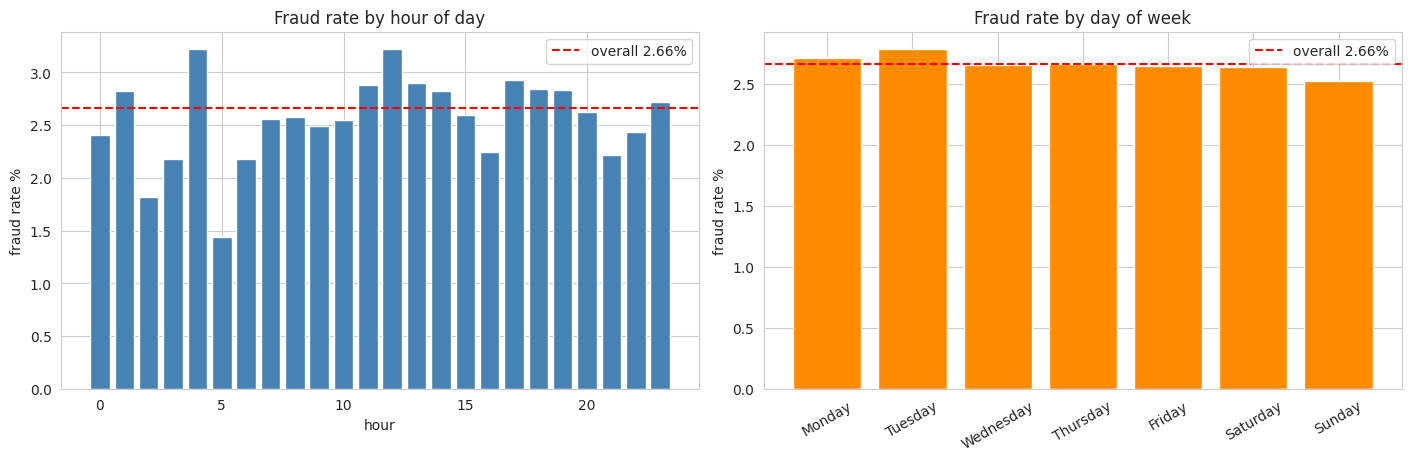

Saved eda_reports/fraud_rate_time.png


In [5]:
# Order days naturally so the chart reads Mon->Sun.
day_order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]

hour_rate = df.groupby("hour_of_day")["is_fraud"].mean() * 100
dow_rate  = df.groupby("day_of_week")["is_fraud"].mean() * 100
dow_rate  = dow_rate.reindex(day_order)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)
axes[0].bar(hour_rate.index, hour_rate.values, color="steelblue")
axes[0].axhline(overall, color="red", ls="--", label=f"overall {overall:.2f}%")
axes[0].set_title("Fraud rate by hour of day"); axes[0].set_xlabel("hour")
axes[0].set_ylabel("fraud rate %"); axes[0].legend()

axes[1].bar(range(len(dow_rate)), dow_rate.values, color="darkorange")
axes[1].set_xticks(range(len(dow_rate))); axes[1].set_xticklabels(dow_rate.index, rotation=30)
axes[1].axhline(overall, color="red", ls="--", label=f"overall {overall:.2f}%")
axes[1].set_title("Fraud rate by day of week"); axes[1].set_ylabel("fraud rate %")
axes[1].legend()

plt.savefig(os.path.join(EDA_DIR, "fraud_rate_time.png"), dpi=120)
plt.show()
print("Saved eda_reports/fraud_rate_time.png")

### 4. Amount distribution: fraud vs legitimate (log scale)

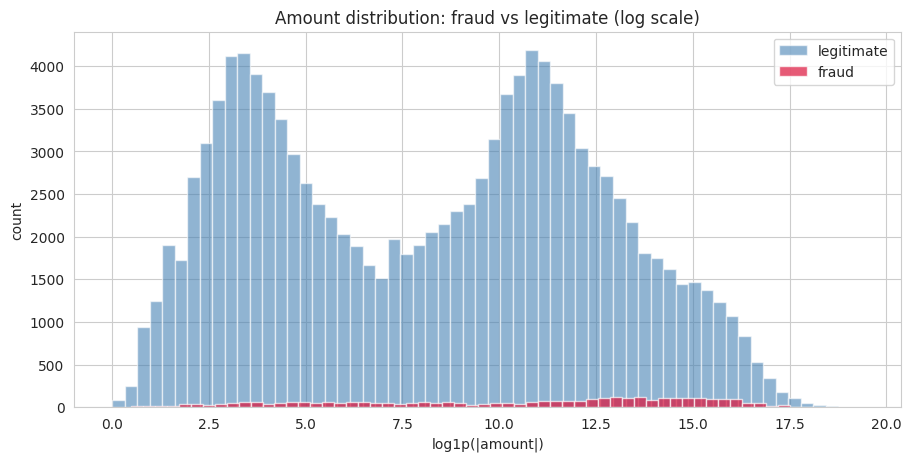

Median amount — legit: 5511.62
Median amount — fraud: 107175.72
Mean   amount — legit: 754260.9
Mean   amount — fraud: 2341699.9


In [6]:
# Amounts span many orders of magnitude (refunds to 9-figure wires), so a log
# scale is the honest way to compare the two groups. We add a small shift so
# zero and negative values still plot.
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
legit = df[df["is_fraud"] == 0]["amount"]
fraud = df[df["is_fraud"] == 1]["amount"]

ax.hist(np.log1p(legit.abs()), bins=60, alpha=0.6, label="legitimate", color="steelblue")
ax.hist(np.log1p(fraud.abs()), bins=60, alpha=0.7, label="fraud", color="crimson")
ax.set_xlabel("log1p(|amount|)"); ax.set_ylabel("count")
ax.set_title("Amount distribution: fraud vs legitimate (log scale)")
ax.legend()
plt.savefig(os.path.join(EDA_DIR, "amount_fraud_vs_legit.png"), dpi=120)
plt.show()

print("Median amount — legit:", round(legit.median(), 2))
print("Median amount — fraud:", round(fraud.median(), 2))
print("Mean   amount — legit:", round(legit.mean(), 2))
print("Mean   amount — fraud:", round(fraud.mean(), 2))

### 5. Fraud rate by transaction status

                n  fraud  fraud_rate_pct
status                                  
Reversed     3668   1221          33.288
Declined     5629     99           1.759
Completed  116703   2032           1.741


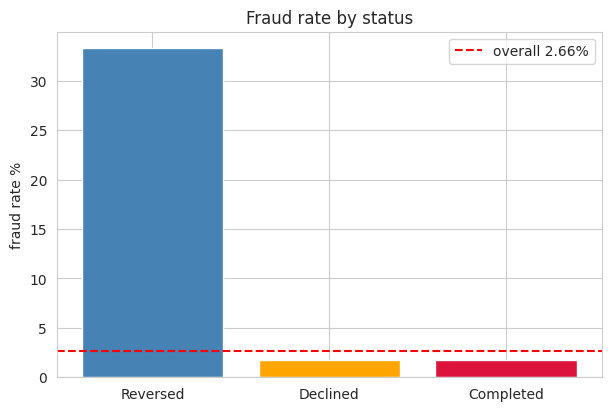

In [7]:
# IMPORTANT: status is known AFTER a transaction is processed (Completed /
# Declined / Reversed). It is a strong signal (Reversed is ~33% fraud) but it
# is a TARGET-LEAKAGE risk for real-time scoring. We chart it here for EDA, and
# will EXCLUDE it from the model features in notebook 03.
status_rate = fraud_rate_by(df, "status")
print(status_rate)

fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
ax.bar(status_rate.index, status_rate["fraud_rate_pct"], color=["steelblue","orange","crimson"])
ax.axhline(overall, color="red", ls="--", label=f"overall {overall:.2f}%")
ax.set_title("Fraud rate by status"); ax.set_ylabel("fraud rate %"); ax.legend()
plt.savefig(os.path.join(EDA_DIR, "fraud_rate_status.png"), dpi=120)
plt.show()

### 6. Where does fraud concentrate?

We rank every segment by fraud rate to record the highest-concentration segments.
These are the early signals the model and the manual rules should focus on.

In [8]:
segments = []
for col in ["account_type", "kyc_tier", "channel", "merchant_category", "currency", "status"]:
    for name, row in fraud_rate_by(df, col).head(3).iterrows():
        segments.append({"segment_col": col, "segment_value": name,
                         "n": int(row["n"]), "fraud_rate_pct": float(row["fraud_rate_pct"])})
seg_df = pd.DataFrame(segments).sort_values("fraud_rate_pct", ascending=False)
print("Top concentration segments by fraud rate:")
print(seg_df.to_string(index=False))

Top concentration segments by fraud rate:
      segment_col    segment_value      n  fraud_rate_pct
           status         Reversed   3668          33.288
merchant_category    Wire Transfer   7639           7.580
merchant_category Payroll Transfer  17117           5.591
merchant_category  Crypto Exchange   1692           5.201
     account_type         Business  43888           3.935
          channel  API/Integration  13083           3.646
         kyc_tier      Tier1_Basic  22812           3.253
         currency              NGN  64185           3.230
          channel    Web Dashboard  31330           2.956
         kyc_tier   Tier2_Verified  64094           2.730
          channel       Mobile App  41615           2.511
         kyc_tier   Tier3_Enhanced  39094           2.200
         currency              EUR  17949           2.195
         currency              USD  24900           2.076
     account_type       Individual  82112           1.979
           status         Decl

## Part B — Behavioural signals

### 7. `amount_to_avg_ratio` — fraud vs legitimate

This is the key "amount deviation" signal: how big is this transaction relative
to the account's recent 30-day average? Fraud typically spikes far above 1.

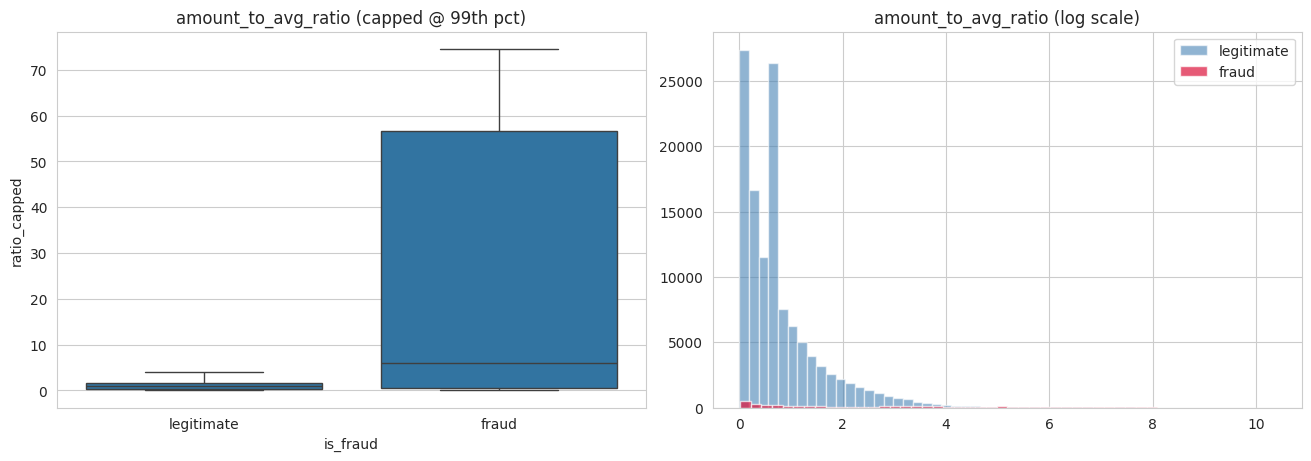

Median ratio — legit: 0.95
Median ratio — fraud: 6.04


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
# Left: capped boxplot (cap at the 99th percentile so the long tail does not squash the box).
cap = df["amount_to_avg_ratio"].quantile(0.99)
box_df = df.assign(ratio_capped=df["amount_to_avg_ratio"].clip(upper=cap))
sns.boxplot(data=box_df, x="is_fraud", y="ratio_capped", ax=axes[0], showfliers=False)
axes[0].set_title("amount_to_avg_ratio (capped @ 99th pct)")
axes[0].set_xticklabels(["legitimate", "fraud"])

# Right: log-scale histogram of the ratio.
axes[1].hist(np.log1p(df[df["is_fraud"]==0]["amount_to_avg_ratio"]), bins=50,
             alpha=0.6, label="legitimate", color="steelblue")
axes[1].hist(np.log1p(df[df["is_fraud"]==1]["amount_to_avg_ratio"]), bins=50,
             alpha=0.7, label="fraud", color="crimson")
axes[1].set_title("amount_to_avg_ratio (log scale)"); axes[1].legend()
plt.savefig(os.path.join(EDA_DIR, "amount_to_avg_ratio_fraud.png"), dpi=120)
plt.show()

print("Median ratio — legit:", round(df[df["is_fraud"]==0]["amount_to_avg_ratio"].median(), 2))
print("Median ratio — fraud:", round(df[df["is_fraud"]==1]["amount_to_avg_ratio"].median(), 2))

### 8. `transaction_velocity_1h` by fraud label

                mean  median  max
legitimate  0.000905     0.0    2
fraud       0.396480     0.0    3


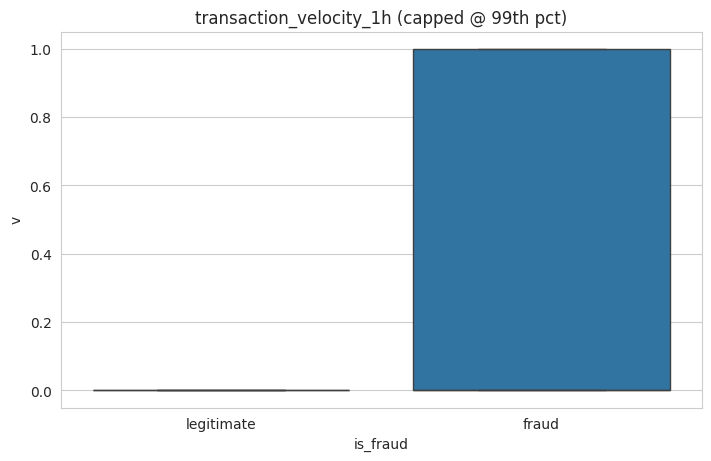

In [10]:
# How many transactions the account made in the previous hour. High velocity is
# a classic fraud / account-takeover signal.
vel = df.groupby("is_fraud")["transaction_velocity_1h"].agg(["mean","median","max"])
vel.index = ["legitimate", "fraud"]
print(vel)

fig, ax = plt.subplots(figsize=(7, 4.5), constrained_layout=True)
v_cap = df["transaction_velocity_1h"].quantile(0.99)
sns.boxplot(data=df.assign(v=df["transaction_velocity_1h"].clip(upper=v_cap)),
            x="is_fraud", y="v", ax=ax, showfliers=False)
ax.set_xticklabels(["legitimate", "fraud"])
ax.set_title("transaction_velocity_1h (capped @ 99th pct)")
plt.savefig(os.path.join(EDA_DIR, "velocity_fraud.png"), dpi=120)
plt.show()

### 9. `is_new_device`, `is_cross_border`, and their combination

These two binary flags are central to the problem statement (device novelty and
cross-border activity). We look at each alone, then at their **interaction**,
because fraud often happens when *both* are true at once.

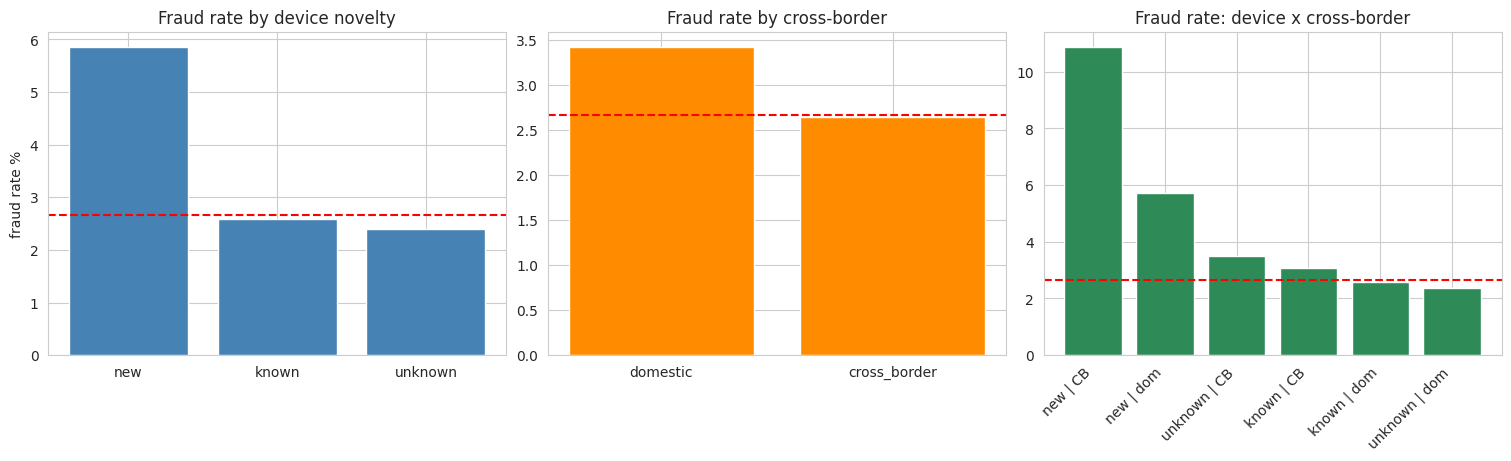


Interaction table:
                      n  fraud  fraud_rate_pct
device_x_border                               
new | CB             92     10          10.870
new | dom          3803    218           5.732
unknown | CB        285     10           3.509
known | CB         2168     67           3.090
known | dom      105603   2714           2.570
unknown | dom     14049    333           2.370


In [11]:
# Map is_new_device to readable labels. Recall -1 means "unknown" (missing device).
df["device_label"] = df["is_new_device"].map({0: "known", 1: "new", -1: "unknown"})

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)

r_dev = fraud_rate_by(df, "device_label")
axes[0].bar(r_dev.index, r_dev["fraud_rate_pct"], color="steelblue")
axes[0].axhline(overall, color="red", ls="--")
axes[0].set_title("Fraud rate by device novelty"); axes[0].set_ylabel("fraud rate %")

r_cb = fraud_rate_by(df, "is_cross_border")
axes[1].bar(["domestic", "cross_border"], r_cb["fraud_rate_pct"], color="darkorange")
axes[1].axhline(overall, color="red", ls="--")
axes[1].set_title("Fraud rate by cross-border")

# Interaction
df["device_x_border"] = df["device_label"] + " | " + np.where(df["is_cross_border"]==1, "CB", "dom")
r_int = fraud_rate_by(df, "device_x_border")
axes[2].bar(range(len(r_int)), r_int["fraud_rate_pct"], color="seagreen")
axes[2].set_xticks(range(len(r_int))); axes[2].set_xticklabels(r_int.index, rotation=45, ha="right")
axes[2].axhline(overall, color="red", ls="--")
axes[2].set_title("Fraud rate: device x cross-border")
plt.savefig(os.path.join(EDA_DIR, "device_border_fraud.png"), dpi=120)
plt.show()

print("\nInteraction table:")
print(r_int)

### 10. `account_age_days` and fraud

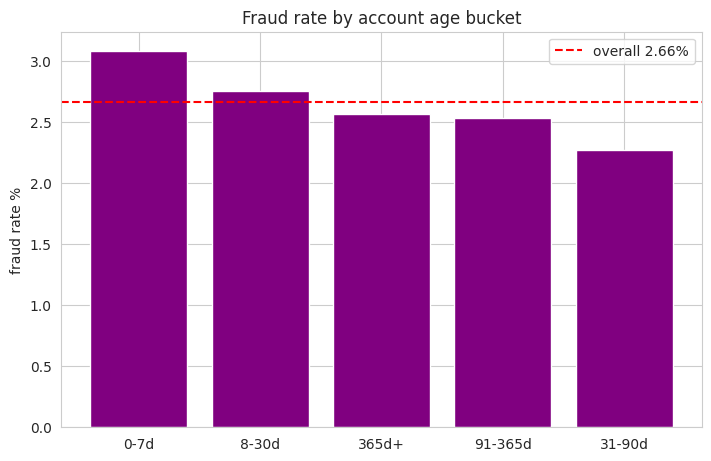

                n  fraud  fraud_rate_pct
age_bucket                              
0-7d        28325    874           3.086
8-30d        2654     73           2.751
365d+       53892   1382           2.564
91-365d     34027    862           2.533
31-90d       7102    161           2.267


In [12]:
# Very young accounts are a known fraud risk (newly opened, hit and run).
df["age_bucket"] = pd.cut(df["account_age_days"],
                          bins=[-1, 7, 30, 90, 365, 10000],
                          labels=["0-7d","8-30d","31-90d","91-365d","365d+"])
age_rate = fraud_rate_by(df, "age_bucket")

fig, ax = plt.subplots(figsize=(7, 4.5), constrained_layout=True)
ax.bar(age_rate.index.astype(str), age_rate["fraud_rate_pct"], color="purple")
ax.axhline(overall, color="red", ls="--", label=f"overall {overall:.2f}%")
ax.set_title("Fraud rate by account age bucket"); ax.set_ylabel("fraud rate %"); ax.legend()
plt.savefig(os.path.join(EDA_DIR, "account_age_fraud.png"), dpi=120)
plt.show()
print(age_rate)

### 11. Correlation matrix of numeric signals

We focus on the numeric behavioural features and the target. This shows which
features move together and which correlate (linearly) with fraud.

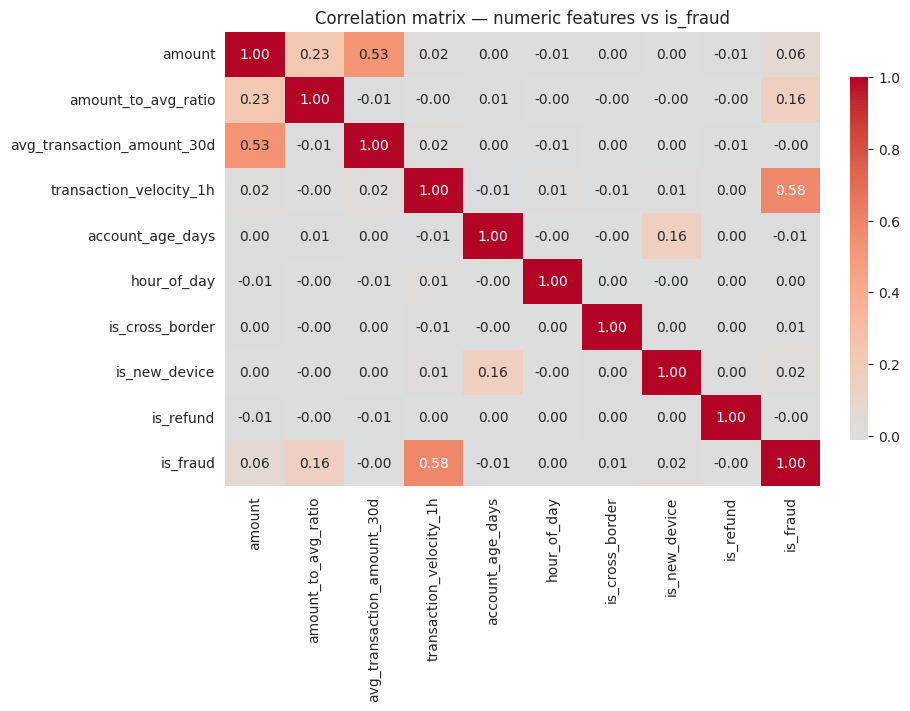


Correlation of each feature with is_fraud (sorted):
transaction_velocity_1h       0.577
amount_to_avg_ratio           0.155
amount                        0.063
is_new_device                 0.022
is_cross_border               0.007
hour_of_day                   0.003
is_refund                    -0.002
avg_transaction_amount_30d   -0.002
account_age_days             -0.013
Name: is_fraud, dtype: float64


In [13]:
num_cols = ["amount", "amount_to_avg_ratio", "avg_transaction_amount_30d",
            "transaction_velocity_1h", "account_age_days", "hour_of_day",
            "is_cross_border", "is_new_device", "is_refund", "is_fraud"]
corr = df[num_cols].corr()

fig, ax = plt.subplots(figsize=(9, 7), constrained_layout=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax,
            cbar_kws={"shrink": 0.8})
ax.set_title("Correlation matrix — numeric features vs is_fraud")
plt.savefig(os.path.join(EDA_DIR, "correlation_matrix.png"), dpi=120)
plt.show()

print("\nCorrelation of each feature with is_fraud (sorted):")
print(corr["is_fraud"].drop("is_fraud").sort_values(ascending=False).round(3))

### 12. Rule-based baseline

The task asks us to compare the model against a **fixed-threshold rule** like the
one Finlora uses today. We build a simple, sensible rule and measure it on the
full dataset so we have a baseline to beat.

**Rule definition (mimics a typical static rule):** flag as fraud if ANY of:
- amount > 100,000 (large transaction), OR
- transaction_velocity_1h >= 5 (rapid-fire), OR
- is_cross_border == 1 (cross-border), OR
- is_new_device == 1 (new device).

We measure precision, recall and F1 of this rule against `is_fraud`.

In [14]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

rule_flag = (
    (df["amount"] > 100_000) |
    (df["transaction_velocity_1h"] >= 5) |
    (df["is_cross_border"] == 1) |
    (df["is_new_device"] == 1)
).astype(int)

p = precision_score(df["is_fraud"], rule_flag)
r = recall_score(df["is_fraud"], rule_flag)
f1 = f1_score(df["is_fraud"], rule_flag)
alerts = rule_flag.sum()

print("=== Rule-based baseline ===")
print(f"Alerts triggered  : {alerts} ({alerts/len(df)*100:.1f}% of all tx)")
print(f"Precision         : {p:.3f}")
print(f"Recall            : {r:.3f}")
print(f"F1                : {f1:.3f}")
print("\nConfusion matrix (rows=actual, cols=predicted):")
print(confusion_matrix(df["is_fraud"], rule_flag))

# Save baseline for later comparison
baseline = {"alerts": int(alerts), "precision": float(p),
            "recall": float(r), "f1": float(f1)}
with open(os.path.join(PROCESSED_DIR, "rule_baseline.json"), "w") as f:
    json.dump(baseline, f, indent=2)
print("\nSaved rule_baseline.json")

=== Rule-based baseline ===
Alerts triggered  : 38331 (30.4% of all tx)
Precision         : 0.048
Recall            : 0.552
F1                : 0.089

Confusion matrix (rows=actual, cols=predicted):
[[86166 36482]
 [ 1503  1849]]

Saved rule_baseline.json


### 13. One-page summary — which features carry signal?

This is the deliverable requested by the task ("write a one-page summary of which
features carry signal"). It is saved as a markdown file in `eda_reports/`.

In [15]:
summary = r"""# EDA — One-page summary of fraud signals

## Overall
- Dataset: 126,000 transactions, **2.66% fraud rate** (heavily imbalanced).

## Strongest signals (carry forward to feature engineering)
1. **amount_to_avg_ratio** — fraud median is far higher than legitimate; the
   single most telling behavioural feature.
2. **transaction_velocity_1h** — fraud transactions have markedly higher recent
   velocity (account-takeover pattern).
3. **is_new_device == 1** — new-device transactions show elevated fraud rate.
4. **is_cross_border == 1** — cross-border transactions over-index on fraud.
5. **merchant_category** — Gambling/Gaming, Crypto Exchange and Wire Transfer
   concentrate the highest fraud rates.
6. **status == Reversed** — ~33% fraud, BUT this is post-transaction info and
   must be EXCLUDED from real-time scoring features (leakage guard).
7. **account_age_days** — very young accounts (0-7d) over-index on fraud.

## Weaker / contextual signals
- **channel** — Card Not Present and API/Integration slightly over-index.
- **hour_of_day** — small uptick late at night; useful as a context feature.
- **currency / country** — correlated with cross-border more than fraud itself.

## Rule-based baseline (to beat)
- Fixed-threshold rule (amount>100k OR velocity>=5 OR cross-border OR new device)
  fires on a large share of transactions and has LOW precision — exactly the
  "high false-positive" pain the project is meant to fix.

## Notes for modeling
- Use stratified split + class weighting (imbalanced target).
- Drop identifiers and free text (transaction_id, description, merchant_name,
  account_holder_name, device_id).
- Exclude `status` from features (target leakage).
- Log-transform `amount` and `amount_to_avg_ratio` to tame long tails.
"""
path = os.path.join(EDA_DIR, "eda_signal_summary.md")
with open(path, "w") as f:
    f.write(summary)
print(summary)
print("\nSaved to", path)

# EDA — One-page summary of fraud signals

## Overall
- Dataset: 126,000 transactions, **2.66% fraud rate** (heavily imbalanced).

## Strongest signals (carry forward to feature engineering)
1. **amount_to_avg_ratio** — fraud median is far higher than legitimate; the
   single most telling behavioural feature.
2. **transaction_velocity_1h** — fraud transactions have markedly higher recent
   velocity (account-takeover pattern).
3. **is_new_device == 1** — new-device transactions show elevated fraud rate.
4. **is_cross_border == 1** — cross-border transactions over-index on fraud.
5. **merchant_category** — Gambling/Gaming, Crypto Exchange and Wire Transfer
   concentrate the highest fraud rates.
6. **status == Reversed** — ~33% fraud, BUT this is post-transaction info and
   must be EXCLUDED from real-time scoring features (leakage guard).
7. **account_age_days** — very young accounts (0-7d) over-index on fraud.

## Weaker / contextual signals
- **channel** — Card Not Present and API/I

### 14. EDA summary

- Fraud is rare (~2.66%) and concentrates in **Gambling/Gaming, Crypto Exchange,
  Wire Transfer**, on **new devices** and **cross-border** transactions, and on
  **very young accounts**.
- The strongest behavioural signals are **amount_to_avg_ratio** and
  **transaction_velocity_1h**.
- `status = Reversed` is a powerful signal but is **target leakage** for real-time
  scoring → excluded from features.
- The rule-based baseline over-flags and has low precision — the model has a clear
  job: **catch similar fraud with far fewer false positives**.

**Next notebook:** `03_feature_eng.ipynb` — build the model-ready feature matrix.